# New Section


DATASET OVERVIEW
         Date        City   PM25   PM10   NO2  Temperature_C  Humidity_Percent
0  2025-01-01       Delhi   28.6  111.6  47.4           15.4                26
1  2025-01-02      Jaipur   59.8  160.7  51.0           30.4                49
2  2025-01-03  Chandigarh  105.0  157.6  40.5           18.4                68
3  2025-01-04  Chandigarh   86.5   55.6  28.9           26.5                33
4  2025-01-05  Chandigarh  134.6  154.1  47.5           51.2                88

DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              600 non-null    object 
 1   City              600 non-null    object 
 2   PM25              585 non-null    float64
 3   PM10              600 non-null    float64
 4   NO2               600 non-null    float64
 5   Temperature_C     600 non-null    float64
 6   Humidity_

/tmp/ipykernel_968/1994156660.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


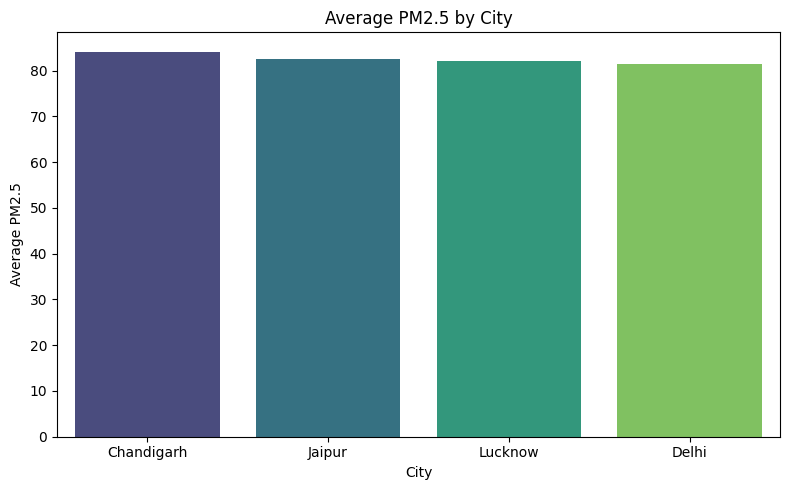

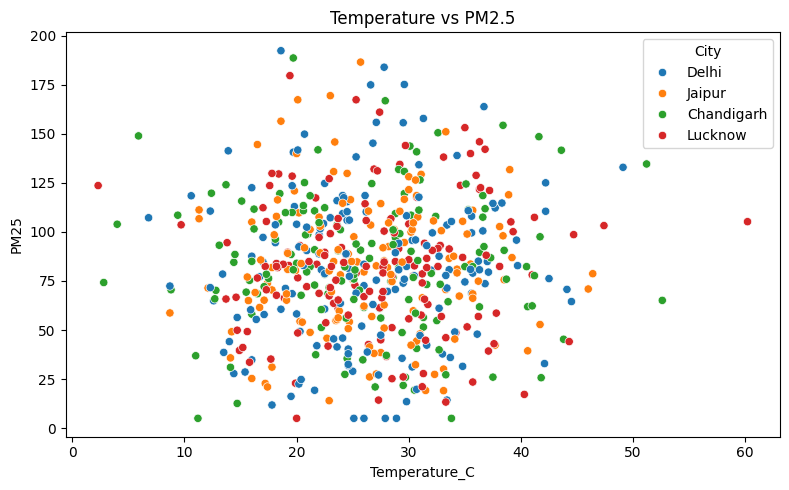

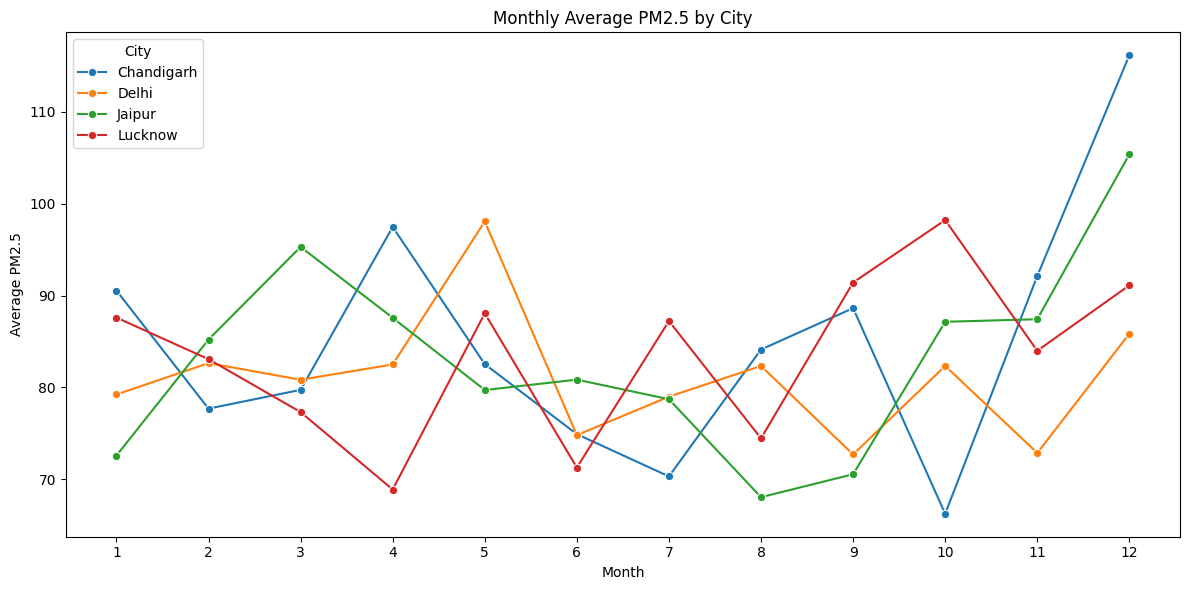

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("04_air_quality.csv")

print("\nDATASET OVERVIEW")
print(df.head())

print("\nDATASET INFO")
print(df.info())

print("\nMISSING VALUES")
print(df.isnull().sum())

df["PM25"] = df.groupby("City")["PM25"].transform(
    lambda x: x.fillna(x.median())
)

df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month

avg_pm25 = df["PM25"].mean()
median_pm25 = df["PM25"].median()
max_pm25 = df["PM25"].max()

print("\nPM2.5 STATISTICS")
print("Average PM2.5 :", round(avg_pm25, 2))
print("Median PM2.5 :", round(median_pm25, 2))
print("Maximum PM2.5 :", round(max_pm25, 2))

city_rank = (
    df.groupby("City")["PM25"]
    .mean()
    .sort_values(ascending=False)
)

print("\nCITY RANKING BY AVERAGE PM2.5")
print(city_rank)

highest_days = df[df["PM25"] == df["PM25"].max()]

print("\nHIGHEST PM2.5 READINGS")
print(highest_days[["Date", "City", "PM25"]])

city_comparison = (
    df.groupby("City")[["PM25", "PM10"]]
    .mean()
)

print("\nCITY WISE PM25 VS PM10")
print(city_comparison)

def air_quality_category(pm):
    if pm <= 50:
        return "Good"
    elif pm <= 100:
        return "Satisfactory"
    elif pm <= 200:
        return "Moderate"
    elif pm <= 300:
        return "Poor"
    elif pm <= 400:
        return "Very Poor"
    else:
        return "Severe"

df["Air_Quality_Category"] = df["PM25"].apply(
    air_quality_category
)

print("\nAIR QUALITY CATEGORY COUNT")
print(df["Air_Quality_Category"].value_counts())

monthly_avg = (
    df.groupby(["City", "Month"])["PM25"]
    .mean()
    .reset_index()
)

print("\nMONTHLY AVERAGE PM2.5")
print(monthly_avg)

std_dev = np.std(df["PM25"])

p25 = np.percentile(df["PM25"], 25)
p50 = np.percentile(df["PM25"], 50)
p75 = np.percentile(df["PM25"], 75)

print("\nNUMPY ANALYSIS")
print("Standard Deviation :", round(std_dev, 2))
print("25th Percentile :", round(p25, 2))
print("50th Percentile :", round(p50, 2))
print("75th Percentile :", round(p75, 2))

Q1 = df["PM25"].quantile(0.25)
Q3 = df["PM25"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

outliers = df[
    (df["PM25"] < lower_limit)
    | (df["PM25"] > upper_limit)
]

print("\nPM2.5 OUTLIERS")
print(outliers[["Date", "City", "PM25"]])

correlation = df["PM25"].corr(df["Temperature_C"])

print("\nCORRELATION BETWEEN TEMPERATURE AND PM2.5")
print(round(correlation, 3))

threshold = 100

above_threshold = (
    (df["PM25"] > threshold).sum()
    / len(df)
) * 100

print("\nPM2.5 ABOVE THRESHOLD")
print(
    f"Percentage of observations above {threshold}: {round(above_threshold,2)}%"
)

plt.figure(figsize=(8,5))
sns.barplot(
    x=city_rank.index,
    y=city_rank.values,
    palette="viridis"
)

plt.title("Average PM2.5 by City")
plt.xlabel("City")
plt.ylabel("Average PM2.5")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x="Temperature_C",
    y="PM25",
    hue="City"
)

plt.title("Temperature vs PM2.5")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))
sns.lineplot(
    data=monthly_avg,
    x="Month",
    y="PM25",
    hue="City",
    marker="o"
)

plt.title("Monthly Average PM2.5 by City")
plt.xlabel("Month")
plt.ylabel("Average PM2.5")
plt.xticks(range(1,13))
plt.tight_layout()
plt.show()